<table class="table table-bordered">
    <tr>
        <th style="text-align:center;"><h1>Data Wrangling</h1><h2>Assignment</h2><h3>Diploma in Data Science</h3></th>
    </tr>
</table>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os


pd.set_option('display.max_columns', 50)

### Step 1: Load and Explore the Data

**What we're predicting**

Baseball's Hall of Fame is the sport's highest individual honour. Each year, a committee votes on which *retired* players deserve to be inducted, and the decision explicitly weighs character and contribution to the game alongside statistics, not just numbers. Induction is rare, and considered the ultimate recognition of a great career.

**The question:** using only a player's career statistics, can we predict whether they will ever be inducted into the Hall of Fame, independent of that human vote?

**Why it matters:** a team's front office could use this to flag potential future Hall of Famers early, giving them concrete, data-driven criteria for who's worth actively campaigning for, well before a human committee ever votes.

**Framing:** this is a binary classification problem. For every player who ever appeared in Major League Baseball, we predict Yes/No, will they ever be inducted, using features built from career batting and pitching totals, drawn from the `Player`, `Batting`, `Pitching` and `HallOfFame` tables.

In [ ]:
from pathlib import Path

# Relative path 
DATA_DIR = Path('data')

player = pd.read_csv(DATA_DIR / 'player.csv')
batting = pd.read_csv(DATA_DIR / 'batting.csv')
pitching = pd.read_csv(DATA_DIR / 'pitching.csv')
hof = pd.read_csv(DATA_DIR / 'hall_of_fame.csv')

for name, df in [('Player', player), ('Batting', batting), ('Pitching', pitching), ('HallOfFame', hof)]:
    print(f"{name}: {df.shape[0]} rows, {df.shape[1]} columns")

Player: 18846 rows, 24 columns
Batting: 101332 rows, 22 columns
Pitching: 44139 rows, 30 columns
HallOfFame: 4120 rows, 9 columns


In [3]:
#First 5 rows of dataframe
player.head()

,player_id,birth_year,birth_month,birth_day,birth_country,birth_state,birth_city,death_year,death_month,death_day,death_country,death_state,death_city,name_first,name_last,name_given,weight,height,bats,throws,debut,final_game,retro_id,bbref_id
0,aardsda01,1981.0,12.0,27.0,USA,CO,Denver,NaN,NaN,NaN,NaN,NaN,NaN,David,Aardsma,David Allan,220.0,75.0,R,R,2004-04-06,2015-08-23,aardd001,aardsda01
1,aaronha01,1934.0,2.0,5.0,USA,AL,Mobile,NaN,NaN,NaN,NaN,NaN,NaN,Hank,Aaron,Henry Louis,180.0,72.0,R,R,1954-04-13,1976-10-03,aaroh101,aaronha01
2,aaronto01,1939.0,8.0,5.0,USA,AL,Mobile,1984.0,8.0,16.0,USA,GA,Atlanta,Tommie,Aaron,Tommie Lee,190.0,75.0,R,R,1962-04-10,1971-09-26,aarot101,aaronto01
3,aasedo01,1954.0,9.0,8.0,USA,CA,Orange,NaN,NaN,NaN,NaN,NaN,NaN,Don,Aase,Donald William,190.0,75.0,R,R,1977-07-26,1990-10-03,aased001,aasedo01
4,abadan01,1972.0,8.0,25.0,USA,FL,Palm Beach,NaN,NaN,NaN,NaN,NaN,NaN,Andy,Abad,Fausto Andres,184.0,73.0,L,L,2001-09-10,2006-04-13,abada001,abadan01


In [4]:
#First 5 rows of dataframe
batting.head()

,player_id,year,stint,team_id,league_id,g,ab,r,h,double,triple,hr,rbi,sb,cs,bb,so,ibb,hbp,sh,sf,g_idp
0,abercda01,1871,1,TRO,NaN,1,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN
1,addybo01,1871,1,RC1,NaN,25,118.0,30.0,32.0,6.0,0.0,0.0,13.0,8.0,1.0,4.0,0.0,NaN,NaN,NaN,NaN,NaN
2,allisar01,1871,1,CL1,NaN,29,137.0,28.0,40.0,4.0,5.0,0.0,19.0,3.0,1.0,2.0,5.0,NaN,NaN,NaN,NaN,NaN
3,allisdo01,1871,1,WS3,NaN,27,133.0,28.0,44.0,10.0,2.0,2.0,27.0,1.0,1.0,0.0,2.0,NaN,NaN,NaN,NaN,NaN
4,ansonca01,1871,1,RC1,NaN,25,120.0,29.0,39.0,11.0,3.0,0.0,16.0,6.0,2.0,2.0,1.0,NaN,NaN,NaN,NaN,NaN


In [5]:
# Same shape as Batting: one row per player per year
pitching.head()

,player_id,year,stint,team_id,league_id,w,l,g,gs,cg,sho,sv,ipouts,h,er,hr,bb,so,baopp,era,ibb,wp,hbp,bk,bfp,gf,r,sh,sf,g_idp
0,bechtge01,1871,1,PH1,NaN,1,2,3,3,2,0,0,78.0,43,23,0,11,1,NaN,7.96,NaN,NaN,NaN,0,NaN,NaN,42,NaN,NaN,NaN
1,brainas01,1871,1,WS3,NaN,12,15,30,30,30,0,0,792.0,361,132,4,37,13,NaN,4.50,NaN,NaN,NaN,0,NaN,NaN,292,NaN,NaN,NaN
2,fergubo01,1871,1,NY2,NaN,0,0,1,0,0,0,0,3.0,8,3,0,0,0,NaN,27.00,NaN,NaN,NaN,0,NaN,NaN,9,NaN,NaN,NaN
3,fishech01,1871,1,RC1,NaN,4,16,24,24,22,1,0,639.0,295,103,3,31,15,NaN,4.35,NaN,NaN,NaN,0,NaN,NaN,257,NaN,NaN,NaN
4,fleetfr01,1871,1,NY2,NaN,0,1,1,1,1,0,0,27.0,20,10,0,3,0,NaN,10.00,NaN,NaN,NaN,0,NaN,NaN,21,NaN,NaN,NaN


In [6]:
# One row per player PER YEAR they were on the ballot.
# category tells us WHO is being voted on (not just players).
# inducted is our target -- but only at the ballot-year level for now.
print(hof.head())
print()
print("category breakdown:")
print(hof['category'].value_counts())
print()
print("inducted breakdown (ballot-year level, not yet player level):")
print(hof['inducted'].value_counts())

   player_id  yearid votedby  ballots  needed  votes inducted category  \
0   cobbty01    1936   BBWAA    226.0   170.0  222.0        Y   Player   
1   ruthba01    1936   BBWAA    226.0   170.0  215.0        Y   Player   
2  wagneho01    1936   BBWAA    226.0   170.0  215.0        Y   Player   
3  mathech01    1936   BBWAA    226.0   170.0  205.0        Y   Player   
4  johnswa01    1936   BBWAA    226.0   170.0  189.0        Y   Player   

  needed_note  
0         NaN  
1         NaN  
2         NaN  
3         NaN  
4         NaN  

category breakdown:
category
Player               3997
Manager                74
Pioneer/Executive      39
Umpire                 10
Name: count, dtype: int64

inducted breakdown (ballot-year level, not yet player level):
inducted
N    3808
Y     312
Name: count, dtype: int64


### Step 2: Data Wrangling on multiple tables 

**What we're doing here**

`Player` has one row per player. `Batting` and `Pitching` have one row per player *per year*. `HallOfFame` has one row per player *per year they were on the ballot*: someone rejected 9 times and inducted on the 10th vote has 10 rows, 9 of them "N".

We need **one row per player** for modelling. So we add up each player's yearly batting and pitching numbers into career totals, collapse HallOfFame down to a single Yes/No per player (were they *ever* inducted, as a Player, not a manager, umpire, or executive), then merge everything on `playerID`.

In [7]:
batting.info()

<class 'pandas.DataFrame'>
RangeIndex: 101332 entries, 0 to 101331
Data columns (total 22 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   player_id  101332 non-null  str    
 1   year       101332 non-null  int64  
 2   stint      101332 non-null  int64  
 3   team_id    101332 non-null  str    
 4   league_id  100595 non-null  str    
 5   g          101332 non-null  int64  
 6   ab         96183 non-null   float64
 7   r          96183 non-null   float64
 8   h          96183 non-null   float64
 9   double     96183 non-null   float64
 10  triple     96183 non-null   float64
 11  hr         96183 non-null   float64
 12  rbi        95759 non-null   float64
 13  sb         94883 non-null   float64
 14  cs         72729 non-null   float64
 15  bb         96183 non-null   float64
 16  so         88345 non-null   float64
 17  ibb        59620 non-null   float64
 18  hbp        93373 non-null   float64
 19  sh         89845 non-null   float6

In [ ]:
# Batting has one row per player per year. Add up career totals per player.
# We drop yearID and stint before summing since adding up "years" or
# "stint numbers" across seasons is meaningless.
batting_career = (
    batting.drop(columns=['year', 'stint'])
    .groupby('player_id')
    .sum(numeric_only=True)
    .reset_index()
)
batting_career.head()

,player_id,g,ab,r,h,double,triple,hr,rbi,sb,cs,bb,so,ibb,hbp,sh,sf,g_idp
0,aardsda01,331,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,1.0,0.0,0.0
1,aaronha01,3298,12364.0,2174.0,3771.0,624.0,98.0,755.0,2297.0,240.0,73.0,1402.0,1383.0,293.0,32.0,21.0,121.0,328.0
2,aaronto01,437,944.0,102.0,216.0,42.0,6.0,13.0,94.0,9.0,8.0,86.0,145.0,3.0,0.0,9.0,6.0,36.0
3,aasedo01,448,5.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,0.0,0.0,0.0,0.0,0.0
4,abadan01,15,21.0,1.0,2.0,0.0,0.0,0.0,0.0,0.0,1.0,4.0,5.0,0.0,0.0,0.0,0.0,1.0


In [9]:
# Same idea for Pitching
pitching_career = (
    pitching.drop(columns=['year', 'stint', 'era', 'baopp'])
    .groupby('player_id')
    .sum(numeric_only=True)
    .reset_index()
)
pitching_career.head()

,player_id,w,l,g,gs,cg,sho,sv,ipouts,h,er,hr,bb,so,ibb,wp,hbp,bk,bfp,gf,r,sh,sf,g_idp
0,aardsda01,16,18,331,0,0,0,69,1011.0,296,160,41,183,340,22.0,12.0,16.0,1,1475.0,141.0,169,17.0,11.0,0.0
1,aasedo01,66,60,448,91,22,5,82,3328.0,1085,468,89,457,641,45.0,21.0,7.0,3,4730.0,234.0,503,0.0,0.0,0.0
2,abadfe01,5,20,258,6,0,0,0,682.0,220,94,32,77,193,7.0,8.0,10.0,0,970.0,66.0,99,7.0,9.0,6.0
3,abbeybe01,22,40,79,66,52,0,1,1704.0,686,285,18,192,161,0.0,18.0,0.0,0,0.0,12.0,442,0.0,0.0,0.0
4,abbeych01,0,0,1,0,0,0,0,6.0,6,1,0,0,0,0.0,1.0,0.0,0,0.0,1.0,3,0.0,0.0,0.0


In [ ]:
# HallOfFame has one row per ballot appearance -> collapse to one row per player.
# We only keep rows where category == 'Player': this table also includes
# managers, umpires and executives, whose playing stats (if any) aren't
# why they were inducted.
hof_player = (
    hof[hof['category'] == 'Player']
    .groupby('player_id')['inducted']
    .apply(lambda x: (x.str.upper() == 'Y').any())
    .reset_index()
    .rename(columns={'inducted': 'inducted_ever'})
)
hof_player['inducted_ever'].value_counts()

inducted_ever
False    942
True     247
Name: count, dtype: int64

In [11]:
data = player.merge(batting_career, on='player_id', how='left')
data = data.merge(pitching_career, on='player_id', how='left', suffixes=('_bat', '_pitch'))
data = data.merge(hof_player, on='player_id', how='left')
data['inducted_ever'] = data['inducted_ever'].fillna(False)
print(data.shape)

(18846, 65)


In [12]:
# This is the imbalance you flagged -- worth seeing the real number
data['inducted_ever'].value_counts(normalize=True)

inducted_ever
False    0.986894
True     0.013106
Name: proportion, dtype: float64

In [ ]:
# checking if batting_career, pitching_career and hof_player reads as 0.
print("Duplicate player_id rows:", data['player_id'].duplicated().sum())

Duplicate player_id rows: 0


### Step 3: Data Cleansing and Transformation

This section handles missing values (structural zeros for batting/pitching stats vs. median imputation for `weight`/`height`), filters out players not yet Hall-of-Fame eligible, evaluates outliers without removing them, encodes categorical features, bins career length, and reduces skew via log transforms before scaling.

In [14]:
non_stat_cols = list(player.columns) + ['inducted_ever']
stat_cols = [c for c in data.columns if c not in non_stat_cols]

print("Missing before fill:")
print(data[stat_cols].isna().sum()[data[stat_cols].isna().sum() > 0])

data[stat_cols] = data[stat_cols].fillna(0)

Missing before fill:
g_bat           187
ab              187
r_bat           187
h_bat           187
double          187
triple          187
hr_bat          187
rbi             187
sb              187
cs              187
bb_bat          187
so_bat          187
ibb_bat         187
hbp_bat         187
sh_bat          187
sf_bat          187
g_idp_bat       187
w              9720
l              9720
g_pitch        9720
gs             9720
cg             9720
sho            9720
sv             9720
ipouts         9720
h_pitch        9720
er             9720
hr_pitch       9720
bb_pitch       9720
so_pitch       9720
ibb_pitch      9720
wp             9720
hbp_pitch      9720
bk             9720
bfp            9720
gf             9720
r_pitch        9720
sh_pitch       9720
sf_pitch       9720
g_idp_pitch    9720
dtype: int64


In [15]:
data['final_game'] = pd.to_datetime(data['final_game'], errors='coerce')
last_year_in_data = batting['year'].max()
print("Last season in this dataset:", last_year_in_data)

not_yet_eligible = (
    data['final_game'].isna() |
    (data['final_game'].dt.year > last_year_in_data - 5)
)
print("Players excluded as not yet HOF-eligible:", not_yet_eligible.sum())

data_eligible = data[~not_yet_eligible].copy()
print("Remaining rows:", data_eligible.shape[0])

Last season in this dataset: 2015
Players excluded as not yet HOF-eligible: 2518
Remaining rows: 16328


In [16]:
q1, q3 = data_eligible['h_bat'].quantile([0.25, 0.75])
iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr
n_outliers = (data_eligible['h_bat'] > upper_bound).sum()
print(f"Players above the IQR outlier threshold for career hits: {n_outliers}")
print(f"Highest career hits in the data: {data_eligible['h_bat'].max()}")

Players above the IQR outlier threshold for career hits: 2693
Highest career hits in the data: 4256.0


In [17]:
suspects = data_eligible[(data_eligible['g_pitch'] > 50) & (data_eligible['ab'] == 0)]
print(f"Players with 50+ games pitched but 0 career at-bats: {len(suspects)}")
print(suspects[['player_id', 'g_bat', 'g_pitch', 'ab']].head(10))

Players with 50+ games pitched but 0 career at-bats: 253
     player_id  g_bat  g_pitch   ab
12   abbotgl01  248.0    248.0  0.0
54    acrema01  114.0    114.0  0.0
272  alvarju01   80.0     80.0  0.0
312  anderbu01   64.0     64.0  0.0
337  anderma01  257.0    257.0  0.0
392  apontlu01  110.0    110.0  0.0
449  arnsbbr01   94.0     94.0  0.0
458  arroyfe01  121.0    121.0  0.0
510  augusdo01   88.0     88.0  0.0
511  augusje01  279.0    279.0  0.0


In [18]:
data_eligible = pd.get_dummies(data_eligible, columns=['bats', 'throws'], dummy_na=True)

def primary_role(row):
    if row['g_pitch'] == 0:
        return 'batter'
    elif row['ab'] == 0:
        return 'pitcher'
    else:
        return 'two_way'

data_eligible['primary_role'] = data_eligible.apply(primary_role, axis=1)
print(data_eligible['primary_role'].value_counts())
data_eligible = pd.get_dummies(data_eligible, columns=['primary_role'])

primary_role
batter     8517
two_way    6356
pitcher    1455
Name: count, dtype: int64


In [19]:
from sklearn.preprocessing import OrdinalEncoder

encoder = OrdinalEncoder()
bats_ordinal = encoder.fit_transform(player[['bats']].fillna('Unknown'))
print("Categories:", encoder.categories_)
print("Distribution:", pd.Series(bats_ordinal.flatten()).value_counts().to_dict())

Categories: [array(['B', 'L', 'R', 'Unknown'], dtype=object)]
Distribution: {2.0: 11615, 1.0: 4877, 3.0: 1191, 0.0: 1163}


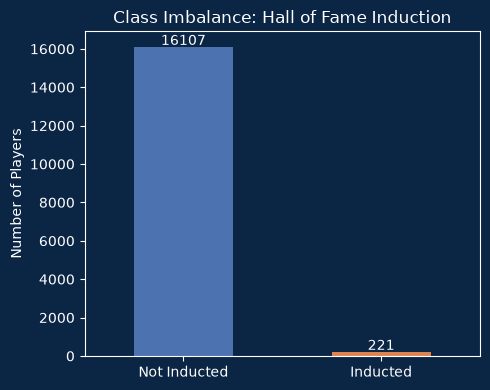

In [ ]:
# I chose this background to match my slides theme
fig, ax = plt.subplots(figsize=(5, 4))

# Same dark-background approach as the confusion matrix
fig.patch.set_facecolor('#0B2545')
ax.set_facecolor('#0B2545')

counts = data_eligible['inducted_ever'].value_counts()
counts.plot(kind='bar', ax=ax, color=['#4C72B0', '#DD8452'])

ax.set_title('Class Imbalance: Hall of Fame Induction', color='white')
ax.set_xticklabels(['Not Inducted', 'Inducted'], rotation=0, color='white')
ax.set_ylabel('Number of Players', color='white')
ax.set_xlabel('')  # "inducted_ever" was the raw column name -- the two bar labels already say enough
ax.tick_params(colors='white')
for spine in ax.spines.values():
    spine.set_color('white')

for i, v in enumerate(counts):
    ax.text(i, v + 100, str(v), ha='center', color='white')

plt.tight_layout()
plt.savefig('class_imbalance.png', transparent=True, dpi=200, bbox_inches='tight')
plt.show()

In [21]:
years_batted = batting.groupby('player_id')['year'].nunique().reset_index().rename(columns={'year': 'years_batted'})
years_pitched = pitching.groupby('player_id')['year'].nunique().reset_index().rename(columns={'year': 'years_pitched'})

data_eligible = data_eligible.merge(years_batted, on='player_id', how='left')
data_eligible = data_eligible.merge(years_pitched, on='player_id', how='left')
data_eligible[['years_batted', 'years_pitched']] = data_eligible[['years_batted', 'years_pitched']].fillna(0)

data_eligible['career_years'] = data_eligible[['years_batted', 'years_pitched']].max(axis=1)

data_eligible['career_length_bucket'] = pd.cut(
    data_eligible['career_years'],
    bins=[-1, 3, 10, 100],
    labels=['short', 'medium', 'long']
)
print(data_eligible['career_length_bucket'].value_counts())
data_eligible = pd.get_dummies(data_eligible, columns=['career_length_bucket'])

career_length_bucket
short     8784
medium    5170
long      2374
Name: count, dtype: int64


In [22]:
from scipy.stats import skew

for col in ['h_bat', 'hr_bat', 'w']:
    raw_skew = skew(data_eligible[col].dropna())
    log_skew = skew(np.log1p(data_eligible[col].dropna()))
    print(f"{col}: raw skew={raw_skew:.2f}, log1p skew={log_skew:.2f}")

for col in ['h_bat', 'hr_bat']:
    data_eligible[f'{col}_log'] = np.log1p(data_eligible[col])

h_bat: raw skew=3.26, log1p skew=0.34
hr_bat: raw skew=6.28, log1p skew=1.51
w: raw skew=4.86, log1p skew=1.55


In [23]:
from sklearn.preprocessing import StandardScaler

exclude_cols = ['player_id', 'birth_year', 'birth_month', 'birth_day', 'birth_country',
                 'birth_state', 'birth_city', 'death_year', 'death_month', 'death_day',
                 'death_country', 'death_state', 'death_city', 'name_first', 'name_last',
                 'name_given', 'debut', 'final_game', 'retro_id', 'bbref_id', 'inducted_ever']

feature_cols = [c for c in data_eligible.select_dtypes(include=[np.number]).columns
                if c not in exclude_cols]

scaler = StandardScaler()
data_scaled = data_eligible.copy()
data_scaled[feature_cols] = scaler.fit_transform(data_eligible[feature_cols])

print(f"{len(feature_cols)} numeric features scaled.")
data_scaled[feature_cols].describe().T[['mean', 'std']].head()

47 numeric features scaled.


,mean,std
weight,-1.141471e-16,1.000032
height,-1.214852e-15,1.000032
g_bat,1.174954e-17,1.000031
ab,1.479572e-17,1.000031
r_bat,-2.959144e-17,1.000031


In [ ]:
# Rate stats: separates "was genuinely good" from "just played a long time,"
# which raw career totals can't do on their own. era_career is also the
# mathematically correct way to get a career ERA (earned runs per 9 innings
# from summed totals) -- unlike summing the yearly era column, which we
# correctly avoided back in Step 2.
data_eligible['batting_avg'] = data_eligible['h_bat'] / data_eligible['ab'].replace(0, np.nan)
data_eligible['hr_rate'] = data_eligible['hr_bat'] / data_eligible['ab'].replace(0, np.nan)
data_eligible['win_pct'] = data_eligible['w'] / (data_eligible['w'] + data_eligible['l']).replace(0, np.nan)
data_eligible['era_career'] = (data_eligible['er'] / (data_eligible['ipouts'] / 3).replace(0, np.nan)) * 9

rate_cols = ['batting_avg', 'hr_rate', 'win_pct', 'era_career']
data_eligible[rate_cols] = data_eligible[rate_cols].fillna(0)

In [ ]:
# Peak-season features: a player's single best year, not just career sum.
# "Compiler vs. peak" is a real, actual debate in how players get voted in --
# your current features only capture the "compiler" side.
batting_peak = (
    batting.groupby('player_id')[['hr', 'rbi', 'h']].max()
    .rename(columns={'hr': 'best_season_hr', 'rbi': 'best_season_rbi', 'h': 'best_season_h'})
    .reset_index()
)
pitching_peak = (
    pitching.groupby('player_id')[['w', 'so']].max()
    .rename(columns={'w': 'best_season_w', 'so': 'best_season_so'})
    .reset_index()
)

data_eligible = data_eligible.merge(batting_peak, on='player_id', how='left')
data_eligible = data_eligible.merge(pitching_peak, on='player_id', how='left')
peak_cols = ['best_season_hr', 'best_season_rbi', 'best_season_h', 'best_season_w', 'best_season_so']
data_eligible[peak_cols] = data_eligible[peak_cols].fillna(0)

### Step 4: Machine Learning Modelling

This section builds a naive baseline and compares it against logistic regression and a decision tree, evaluated on precision/recall/F1 given the severe class imbalance, then investigates a multicollinearity finding in the logistic regression's coefficients via L1 regularisation and PCA.

In [39]:
exclude_cols = ['player_id', 'birth_year', 'birth_month', 'birth_day', 'birth_country',
                 'birth_state', 'birth_city', 'death_year', 'death_month', 'death_day',
                 'death_country', 'death_state', 'death_city', 'name_first', 'name_last',
                 'name_given', 'debut', 'final_game', 'retro_id', 'bbref_id', 'inducted_ever']

feature_cols = [c for c in data_eligible.select_dtypes(include=[np.number]).columns
                if c not in exclude_cols]

X = data_eligible[feature_cols]
print("Missing values before imputation:")
print(X.isna().sum()[X.isna().sum() > 0])

y = data_eligible['inducted_ever'].fillna(False).astype(bool)
y = data_eligible['inducted_ever'].fillna(False).astype(bool)

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


# test-set information into training.
train_median = X_train.median()
X_train = X_train.fillna(train_median)
X_test = X_test.fillna(train_median)

print(f"Train: {X_train.shape[0]} players ({y_train.sum()} inducted)")
print(f"Test: {X_test.shape[0]} players ({y_test.sum()} inducted)")

Missing values before imputation:
weight    766
height    700
dtype: int64
Train: 13062 players (177 inducted)
Test: 3266 players (44 inducted)


In [27]:
from sklearn.metrics import classification_report

baseline_pred = np.zeros(len(y_test), dtype=bool)

print("Naive baseline (always predict No):")
print(classification_report(y_test, baseline_pred, zero_division=0.0))

Naive baseline (always predict No):
              precision    recall  f1-score   support

       False       0.99      1.00      0.99      3222
        True       0.00      0.00      0.00        44

    accuracy                           0.99      3266
   macro avg       0.49      0.50      0.50      3266
weighted avg       0.97      0.99      0.98      3266



In [28]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

logreg = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
logreg.fit(X_train_scaled, y_train)

logreg_pred = logreg.predict(X_test_scaled)

print("Logistic regression:")
print(classification_report(y_test, logreg_pred, zero_division=0))

Logistic regression:
              precision    recall  f1-score   support

       False       1.00      0.97      0.99      3222
        True       0.34      0.95      0.50        44

    accuracy                           0.97      3266
   macro avg       0.67      0.96      0.74      3266
weighted avg       0.99      0.97      0.98      3266



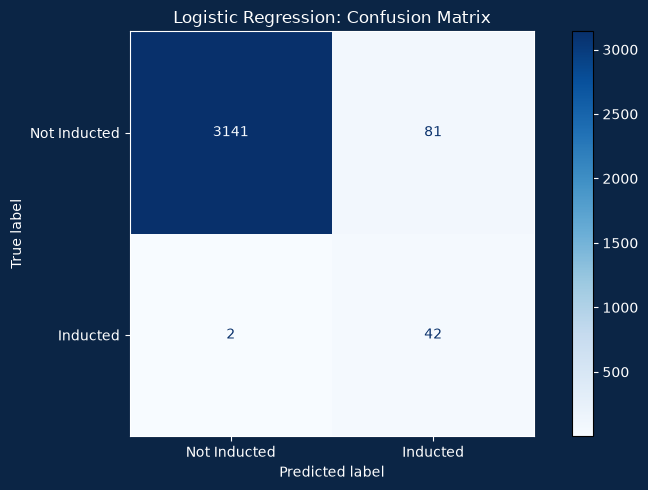

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(8, 5))

fig.patch.set_facecolor('#0B2545')
ax.set_facecolor('#0B2545')

disp = ConfusionMatrixDisplay.from_predictions(
    y_test, logreg_pred, display_labels=['Not Inducted', 'Inducted'], cmap='Blues', ax=ax
)


# that cell's own shade, so overriding it would break readability there.
ax.set_title('Logistic Regression: Confusion Matrix', color='white')
ax.xaxis.label.set_color('white')
ax.yaxis.label.set_color('white')
ax.tick_params(colors='white')
for spine in ax.spines.values():
    spine.set_color('white')

# The colorbar strip on the right is a separate axes sklearn attaches --
# its tick numbers (500, 1000, 1500...) need the same treatment
cbar_ax = fig.axes[-1]
cbar_ax.set_facecolor('#0B2545')
cbar_ax.yaxis.set_tick_params(color='white')
plt.setp(cbar_ax.get_yticklabels(), color='white')

plt.tight_layout()
plt.savefig('confusion_matrix.png', transparent=True, dpi=200, bbox_inches='tight')
plt.show()

In [30]:
from sklearn.preprocessing import RobustScaler

robust_scaler = RobustScaler()
X_train_robust = robust_scaler.fit_transform(X_train)
X_test_robust = robust_scaler.transform(X_test)

logreg_robust = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
logreg_robust.fit(X_train_robust, y_train)
logreg_robust_pred = logreg_robust.predict(X_test_robust)

print("Logistic regression (RobustScaler):")
print(classification_report(y_test, logreg_robust_pred, zero_division=0.0))

Logistic regression (RobustScaler):
              precision    recall  f1-score   support

       False       1.00      0.98      0.99      3222
        True       0.34      0.95      0.51        44

    accuracy                           0.97      3266
   macro avg       0.67      0.96      0.75      3266
weighted avg       0.99      0.97      0.98      3266



In [31]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42)
tree.fit(X_train, y_train)

tree_pred = tree.predict(X_test)

print("Decision tree:")
print(classification_report(y_test, tree_pred, zero_division=0))

Decision tree:
              precision    recall  f1-score   support

       False       1.00      0.94      0.97      3222
        True       0.18      0.93      0.30        44

    accuracy                           0.94      3266
   macro avg       0.59      0.94      0.63      3266
weighted avg       0.99      0.94      0.96      3266



In [32]:
from sklearn.metrics import f1_score, precision_score, recall_score

results = pd.DataFrame({
    'model': ['Naive baseline', 'Logistic regression', 'Decision tree'],
    'precision': [precision_score(y_test, p, zero_division=0) for p in [baseline_pred, logreg_pred, tree_pred]],
    'recall': [recall_score(y_test, p, zero_division=0) for p in [baseline_pred, logreg_pred, tree_pred]],
    'f1': [f1_score(y_test, p, zero_division=0) for p in [baseline_pred, logreg_pred, tree_pred]],
})
results

,model,precision,recall,f1
0,Naive baseline,0.000000,0.000000,0.000000
1,Logistic regression,0.341463,0.954545,0.502994
2,Decision tree,0.177489,0.931818,0.298182


In [33]:
coef_df = pd.DataFrame({
    'feature': feature_cols,
    'logreg_coefficient': logreg.coef_[0],
}).sort_values('logreg_coefficient', ascending=False)

print("Top 10 features pushing toward 'inducted':")
print(coef_df.head(10))
print()
print("Top 10 features pushing toward 'not inducted':")
print(coef_df.tail(10))

Top 10 features pushing toward 'inducted':
            feature  logreg_coefficient
5             h_bat            4.615887
19                w            2.749222
26           ipouts            1.495443
37               gf            1.441087
27          h_pitch            0.974927
31         so_pitch            0.949448
52  best_season_rbi            0.941785
8            hr_bat            0.835509
45        h_bat_log            0.815927
12           bb_bat            0.629133

Top 10 features pushing toward 'not inducted':
          feature  logreg_coefficient
47    batting_avg           -0.537488
13         so_bat           -0.651025
38        r_pitch           -0.787700
54  best_season_w           -0.815939
3              ab           -1.371341
50     era_career           -1.387366
53  best_season_h           -1.828498
2           g_bat           -1.905347
22             gs           -2.215095
21        g_pitch           -2.748588


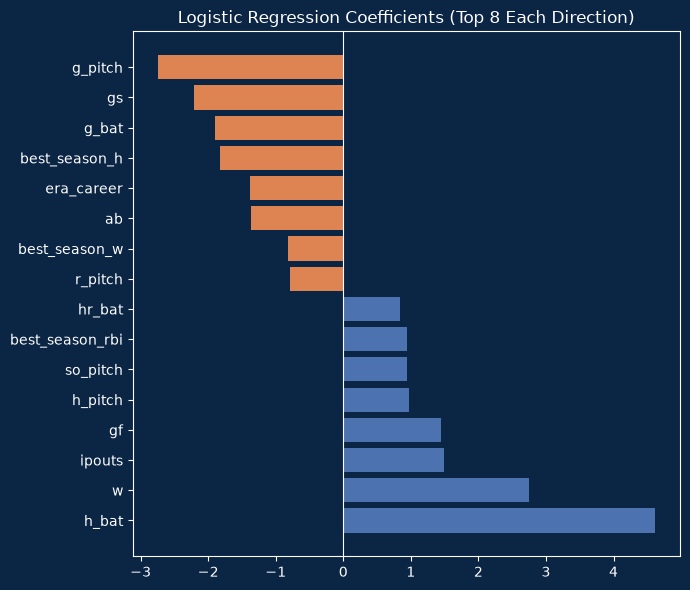

In [34]:
top_features = pd.concat([coef_df.head(8), coef_df.tail(8)])

fig, ax = plt.subplots(figsize=(7, 6))
fig.patch.set_facecolor('#0B2545')
ax.set_facecolor('#0B2545')

colors = ['#DD8452' if v < 0 else '#4C72B0' for v in top_features['logreg_coefficient']]
ax.barh(top_features['feature'], top_features['logreg_coefficient'], color=colors)

# Was color='black' -- invisible on this background, and this line is the
# actual boundary between "pushes toward inducted" and "pushes toward not,"
# not just decoration, so it needs to survive the theme change
ax.axvline(0, color='white', linewidth=0.8)

ax.set_title('Logistic Regression Coefficients (Top 8 Each Direction)', color='white')
ax.tick_params(colors='white')
for spine in ax.spines.values():
    spine.set_color('white')

plt.tight_layout()
plt.savefig('coefficients.png', transparent=True, dpi=200, bbox_inches='tight')
plt.show()

In [35]:
logreg_l1 = LogisticRegression(penalty='l1', solver='liblinear', class_weight='balanced', random_state=42)
logreg_l1.fit(X_train_scaled, y_train)
logreg_l1_pred = logreg_l1.predict(X_test_scaled)

print("Logistic regression (L1):")
print(classification_report(y_test, logreg_l1_pred, zero_division=0.0))

coef_l1_df = pd.DataFrame({
    'feature': feature_cols,
    'l2_coefficient': logreg.coef_[0],
    'l1_coefficient': logreg_l1.coef_[0],
}).sort_values('l1_coefficient', ascending=False)

print(f"\nFeatures zeroed out by L1: {(coef_l1_df['l1_coefficient'] == 0).sum()} of {len(feature_cols)}")
print(coef_l1_df.head(10))
print(coef_l1_df.tail(10))

Logistic regression (L1):
              precision    recall  f1-score   support

       False       1.00      0.97      0.99      3222
        True       0.33      0.95      0.49        44

    accuracy                           0.97      3266
   macro avg       0.67      0.96      0.74      3266
weighted avg       0.99      0.97      0.98      3266


Features zeroed out by L1: 2 of 56
            feature  l2_coefficient  l1_coefficient
5             h_bat        4.615887        6.646021
26           ipouts        1.495443        3.785225
19                w        2.749222        3.006167
37               gf        1.441087        1.473798
45        h_bat_log        0.815927        1.115720
52  best_season_rbi        0.941785        1.011418
8            hr_bat        0.835509        0.910247
31         so_pitch        0.949448        0.810279
12           bb_bat        0.629133        0.694494
49          win_pct        0.491098        0.466987
          feature  l2_coefficient  l1_c

In [ ]:
from sklearn.decomposition import PCA

# PCA needs scaled input: it looks for directions of maximum variance, and
# unscaled features (games in the hundreds vs height in inches) would
# dominate the components from raw scale alone, not real signal. Fit on
# train only, same rule as scaling and imputation.
pca_full = PCA(random_state=42)
pca_full.fit(X_train_scaled)

cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)
n_components_90 = np.argmax(cumulative_variance >= 0.90) + 1

print(f"Components needed to explain 90% of variance: {n_components_90} (out of {X_train_scaled.shape[1]} original features)")
print(f"First 5 components alone explain: {cumulative_variance[4]:.3f}")

Components needed to explain 90% of variance: 12 (out of 56 original features)
First 5 components alone explain: 0.790


In [37]:
pca = PCA(n_components=n_components_90, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

logreg_pca = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
logreg_pca.fit(X_train_pca, y_train)
logreg_pca_pred = logreg_pca.predict(X_test_pca)

print(f"Logistic regression on {n_components_90} PCA components:")
print(classification_report(y_test, logreg_pca_pred, zero_division=0.0))

results_pca = pd.concat([results, pd.DataFrame({
    'model': ['Logistic regression (PCA)'],
    'precision': [precision_score(y_test, logreg_pca_pred, zero_division=0)],
    'recall': [recall_score(y_test, logreg_pca_pred, zero_division=0)],
    'f1': [f1_score(y_test, logreg_pca_pred, zero_division=0)],
})], ignore_index=True)
results_pca

Logistic regression on 12 PCA components:
              precision    recall  f1-score   support

       False       1.00      0.96      0.98      3222
        True       0.25      0.98      0.39        44

    accuracy                           0.96      3266
   macro avg       0.62      0.97      0.69      3266
weighted avg       0.99      0.96      0.97      3266



,model,precision,recall,f1
0,Naive baseline,0.000000,0.000000,0.000000
1,Logistic regression,0.341463,0.954545,0.502994
2,Decision tree,0.177489,0.931818,0.298182
3,Logistic regression (PCA),0.245714,0.977273,0.392694


## Report
### 1. Table of Contents
2. Introduction with Value Based Problem Statement
3. Problem Formulation
4. Data Wrangling on Multiple Tables
5. Data Cleansing and Transformation
6. Machine Learning Model
7. Summary and Further Improvements
7a. Recommendations
8. Reflection

### 2. Introduction with Value Based Problem Statement

Each year, a small committee decides which retired Major League Baseball players are inducted into the Hall of Fame, the sport's highest individual honour. Induction is rare and carries enormous prestige, and the decision explicitly weighs character, sportsmanship, and contribution to the game alongside on-field performance, not statistics alone.

This project asks a narrower, more workable question: can a player's statistical Hall of Fame case be identified directly from their career numbers? We frame this as a binary classification problem, predicting for any player who has ever appeared in MLB whether they will ever be inducted, using features built entirely from their career batting and pitching record.

The value case is for a team's front office: rather than a flat prediction, the model's real output is which specific career statistics most strongly drive induction odds, giving concrete, data-driven criteria for deciding which retiring players are worth actively campaigning for, well before a human committee ever votes.

### 3. Problem Formulation

Four tables from the Baseball Databank (Lahman) dataset were used: `Player` (18,846 rows, one per player), `Batting` and `Pitching` (101,332 and 44,139 rows respectively, one row per player per season), and `HallOfFame` (4,120 rows, one row per player per year they appeared on a Hall of Fame ballot, spanning four voting categories: Player, Manager, Pioneer/Executive, and Umpire).

Exploration surfaced the central design decision this problem required before any wrangling could begin: which population of players to model. `HallOfFame` contains only the 1,189 players who ever appeared on a ballot as a Player, a comparatively moderate split (79.2% not inducted vs. 20.8% inducted) if the problem is restricted to that group. Extending the population to every player who ever appeared in MLB, including the many thousands never seriously considered, produces a far more extreme imbalance instead. We chose the latter framing. The project's value case, a front office identifying Hall-of-Fame-calibre value before it's already publicly obvious, requires evaluating players who were never on a ballot at all, not just re-ranking players already recognized as candidates. This decision was made explicit early, since it determines both the class balance the model must handle and the difficulty of the underlying task.

The problem is therefore formulated as binary classification: for every player in `Player` who has completed their career, predict `inducted_ever` (Yes/No) using features derived from career batting and pitching statistics. Exploration of `HallOfFame` also revealed that its natural grain is one row per ballot appearance, not one row per player, and that its `category` field covers non-players. Both had to be resolved before the target variable itself could be constructed, addressed in the next section.

### 4. Data Wrangling on Multiple Tables

The four source tables share a join key (`player_id`) but differ in grain, which had to be resolved before they could be combined. `Player` is already one row per player. `Batting` and `Pitching` are one row per player per season, so a player with a fifteen-season career contributes fifteen rows. Following the aggregation approach for transactional and time-series-style data, where summary statistics are computed per entity, each was aggregated to one row per player: career totals via `groupby('player_id').sum()`, and, added later to capture single-season peak performance alongside career accumulation, best-season totals via the equivalent `.max()`. Year and stint identifiers were dropped before aggregation, since summing them across seasons is meaningless. `era` and `baopp` were also dropped from `Pitching`, as these are rate statistics and summing a rate across seasons produces an invalid number. A mathematically valid career ERA was later reconstructed in Step 3 from summed earned runs and innings pitched, rather than by summing the yearly rate column.

`HallOfFame` required a different transformation: it is one row per player per ballot year per voting method, so a player rejected several times before eventual induction accumulates multiple "N" rows and one "Y" row. This was filtered to `category == 'Player'`, excluding Managers, Umpires, and Executives, whose inclusion would otherwise merge irrelevant playing statistics onto their rows, then collapsed to a single boolean per player (`inducted_ever`, true if any ballot appearance was "Y").

The four resulting tables were merged on `player_id`. Because `Batting` and `Pitching` share several column names (`g`, `h`, and `hr`, among others), suffixes (`_bat`/`_pitch`) were applied during the merge to avoid silently overwriting one with the other. Players absent from `HallOfFame` entirely were treated as `inducted_ever = False`, since absence means never appearing on a ballot at all. The final table contains 18,846 rows and 65 columns, one row per player, with zero duplicate `player_id` values confirmed after merging: this verified that the aggregation steps had correctly reduced each source table to a unique key before joining.

### 5. Data Cleansing and Transformation

Two distinct missing-value patterns required different treatment. Batting and pitching columns were `NaN` only for players entirely absent from that source table (a pure pitcher with zero batting rows, for instance), reflecting structural absence rather than unknown data, so these were filled with 0 rather than a statistical estimate. `weight` and `height`, by contrast, were genuinely unrecorded for some players (766 and 700 respectively, concentrated among 19th-century players) and were imputed with the median, since a value of 0 would be nonsensical for a physical measurement. These are two different imputation techniques for two different reasons, and the median itself is computed from the training set only, then applied to both train and test, to avoid leaking test-set information into the fitted value.

A further data-quality issue was addressed before modelling: players still active, or retired too recently to have been ballot-eligible, would otherwise appear as false negatives. Using `final_game`, players missing this date or retired within five years of the dataset's final season (2015) were excluded, removing 2,518 players and leaving 16,328.

Outliers were evaluated using an IQR check on career hits, which flagged 2,693 players, the highest being 4,256, the genuine all-time MLB record, a useful confirmation that the pipeline was producing correct numbers. Both trimming and capping were considered and deliberately rejected: the players furthest from the median statistically are disproportionately the Hall-of-Fame-calibre careers the model is built to identify, so removing or compressing them would remove the target signal itself. A bar chart of the resulting class split (16,107 not inducted vs. 221 inducted) makes the scale of that imbalance visible.

Categorical variables (`bats`, `throws`, a binned `career_length_bucket`, and a derived `primary_role` flag) were one-hot encoded. An initial version of `primary_role` classified any player with at least one batting-table row as a "batter," which returned zero players in the "pitcher" category, an implausible result given how many pitchers rarely bat. A check confirmed the cause: 253 players have 50 or more games pitched but zero career at-bats, meaning `Batting.csv` logs a game appearance even for pitchers who never actually batted. Rebuilding the flag against at-bats rather than games gave a more credible three-way split of 8,517 batters, 6,356 two-way players, and 1,455 pitchers. Batting handedness was also tested with ordinal encoding as a second approach for comparison against one-hot, but rejected: left, right, and both-handed batting have no true order between them, so treating them as ranked integers would introduce a false relationship the one-hot version avoids.

Career hits, home runs, and pitching wins were heavily right-skewed (skewness of 3.26, 6.28, and 4.86 respectively); a log(1+x) transform reduced this substantially (to 0.34, 1.51, and 1.55). Numeric features were then standardised (zero mean, unit variance) using `StandardScaler`. A Robust Scaler, sometimes recommended when outliers are retained rather than removed, was tested as a second approach in Step 4 rather than assumed superior; the result is discussed with the other model comparisons in the next section.

### 6. Machine Learning Model

Data was split 80/20 into train and test sets, stratified on the target to preserve the 1.3% positive rate in both (177 of 13,062 inducted in train; 44 of 3,266 in test). A naive baseline, always predicting "not inducted," scored 99% accuracy but 0% precision and recall on the positive class, confirming accuracy alone is unsuitable given the imbalance; precision, recall, and F1 were used throughout instead.

Two models were compared against this baseline: logistic regression (`class_weight='balanced'`, scaled features) and a depth-limited decision tree (`max_depth=5`, unscaled features, since trees do not require scaling). Logistic regression reached precision 0.34, recall 0.95, F1 0.50; the decision tree reached precision 0.18, recall 0.93, F1 0.30. Both substantially outperformed the baseline's F1 of 0.00, correctly identifying the large majority of true Hall of Famers at the cost of a meaningful number of false positives, a trade-off worth accepting for a first-pass screening tool, where a missed candidate costs more than an extra one for a human to review. A confusion matrix for the logistic regression model and a chart of its strongest coefficients in each direction are included alongside this analysis.

Two fixes made earlier in the pipeline, a train-only median for the imputation leak and a corrected `primary_role` split, changed neither model's metrics at the precision shown here. Both were still worth making: the leak was a genuine methodological error even though only two low-influence features were affected, and the corrected role split is now internally consistent even if the model had already captured similar information through other pitching-volume features such as `g_pitch` and `ipouts`. A Robust Scaler was also tested as a second scaling approach, given career totals include the outliers retained in Step 3; it produced results within a rounding error of `StandardScaler` (precision 0.34, recall 0.95, F1 0.51), suggesting the choice between the two scalers made little practical difference for this model.

Examining the logistic regression's coefficients surfaced a methodological finding: several features had signs contradicting baseball logic in isolation. `g_pitch` (games pitched) was the single most negative coefficient (-2.75) despite `w` (wins, +2.75) and `ipouts` (innings pitched, +1.50) being strongly positive, which is inconsistent given wins and innings cannot accumulate without games pitched. This was investigated as multicollinearity: an L1-regularised variant zeroed out only 2 of 56 features, and a PCA experiment (56 features compressed to 12 components for 90% of variance) confirmed substantial redundancy but reduced F1 to 0.39 rather than improving it. Together these indicate the correlated features are jointly informative for this rare class rather than simply duplicated, so the redundancy could not be removed without a cost to predictive performance.

### 7. Summary and Further Improvements

The final logistic regression model (F1 = 0.50) is the strongest result obtained, correctly identifying 95% of true Hall of Famers in the test set at 34% precision, a substantial improvement over a naive baseline that identifies none. This supports the project's underlying premise: career statistics alone carry meaningful signal about Hall of Fame induction, independent of the voting process.

Two earlier issues were corrected, not just documented. The median used to impute missing weight/height values is now calculated from the training set alone, matching the same principle already applied correctly to scaling and L1 fitting. The `primary_role` feature, which originally returned zero "pitcher" players, was rebuilt against at-bats rather than games once a diagnostic confirmed the original logic was wrong, producing a credible three-way split. Neither fix changed the model's headline metrics: both were real errors with limited influence on this particular model's output.

One limitation remains open. Adding rate and peak-season features improved the logistic regression's F1 slightly (0.49 to 0.50) but reduced the decision tree's substantially (0.48 to 0.30). With only 44 positive test examples, this may reflect the tree's fixed depth struggling with the extra correlated features rather than genuine deterioration, and would need cross-validation across several splits to confirm either way. A small discrepancy also remains between the inducted-player count in Step 2 (247) and the number surviving the eligibility filter in Step 4 (221), likely a handful of pre-1900s inductees with missing or unparseable `final_game` dates wrongly excluded as not-yet-eligible.

Further improvements: adding `PlayerAward` (All-Star and MVP counts) as a fifth table would likely add strong predictive signal; `Fielding` data was not used and may help distinguish defensive specialists; and a missing-value indicator alongside the median imputation may better capture whether the physical-data gap is itself informative of a player's era.

### 7a. Recommendations
The logistic regression's coefficients give concrete guidance for a team's front office deciding which retiring players are worth actively campaigning for.

The clearest signal is career accumulation, not single-season brilliance. Career hits, wins, and innings pitched were the three strongest positive predictors, so front offices should prioritize tracking and publicizing these specific counting totals as a player approaches retirement, rather than building a case around efficiency stats like batting average, which showed a weaker, less reliable relationship with induction. A standout best-season RBI total was also a meaningful positive signal, worth highlighting specifically when a player had one genuinely exceptional year.

One caution worth adding: raw volume-of-play stats, games pitched in particular, behaved counterintuitively once several correlated statistics were considered together (see Section 6's multicollinearity discussion). A front office should lean on the specific, less ambiguous totals, hits and wins directly, rather than reasoning from any single volume metric in isolation.

Since Hall of Fame voting itself explicitly weighs character and reputation alongside statistics, this model is best used as an internal front-office signal for where to invest campaigning effort, not as a substitute for the human judgement the actual vote requires.

### 8. Reflection

This assignment connected directly to each week's stated learning objectives rather than feeling like separable exercises. Lecture 1's six-step framework (Discovering, Structuring, Cleaning, Enriching, Validating) mapped cleanly onto Steps 1 to 4, and made the iterative nature of data wrangling concrete. Several "Validating" moments, a duplicate-key check, an implausible zero count in a derived feature, a discrepancy in inducted-player totals, only surfaced after Structuring and Cleaning were apparently complete, each sending the work back to an earlier step rather than continuing in one straight line.

The most valuable lesson was not any single technique but a principle repeated across Lectures 2, 3, and 5 for imputation, encoding, and scaling: preprocessing parameters must be learned from training data only. Applying it correctly to scaling from the start, missing it for median imputation, then catching and correcting that gap once it was pointed out, was a more complete demonstration of the principle than getting it right everywhere the first time would have been.

Lecture 7's aggregation techniques and Lecture 5's domain-driven feature computation were the two techniques most directly responsible for the model's actual predictive performance, reinforcing that feature engineering mattered more here than model choice.